# Guider focus error per mm of M2_OFF3

`pfs.drp.qa.guiders.coordinates.GUIDER_FOCUS_UM_PER_M2_OFF3_MM` converts between a guider focus error (µm, as
`analysis.estimateFocusErrors` measures it with ics_agActor's calibration) and a change of M2_OFF3 (mm). The focus
plots use it for the focus error expected about a chosen M2_OFF3 and for their M2_OFF3 axis
([`guider-plots.ipynb`](guider-plots.ipynb)). This notebook measures it, and is where the value comes from:

**650 µm of guider focus error per mm of M2_OFF3, good to about 10%.**

The measurement is the slope of the focus error against M2_OFF3 near best focus, fitted on each AG focus sweep in the
opdb (`analysis.fitFocusSlope`), and the median of those slopes. An AG focus sweep is an IIC sequence of type
`agFocusSweep`: one visit, AG exposures only, stepping M2_OFF3 through focus at seven positions with three exposures
at each. They are taken at the start of most nights, from 2025-03-20.

It needs an opdb with the sweeps' `agc_data` (about 450,000 rows; a few seconds from a local copy). Run it again when
there are sweeps to add:

```
OPDB_HOST=... OPDB_PORT=... jupyter nbconvert --to notebook --execute --inplace docs/guider-focus-slope.ipynb
```

In [1]:
%matplotlib inline

import logging
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pfs.drp.qa.guiders import analysis, coordinates, queries
from pfs.utils import agMetrics
from pfs.utils.database.opdb import OpDB
from pfs.utils.datamodel.ag import SourceMatchingFlags

plt.rcParams["figure.dpi"] = 72
logging.getLogger(queries.__name__).setLevel(logging.ERROR)  # sweeps with no AG data are counted below

# The read-only user of the summit's replica, unless the environment names another opdb.
opdb = OpDB(
    host=os.environ.get("OPDB_HOST", "pfsa-db"),
    port=int(os.environ.get("OPDB_PORT", 5432)),
    user=os.environ.get("OPDB_USER", "public_user"),
    dbname="opdb",
)

HALF_RANGE_MM = 0.2  # fit the exposures within this of a sweep's best focus


def robustScatter(values) -> float:
    """Return 1.4826 times the median absolute deviation: the sigma of a Gaussian."""
    values = np.asarray(values, dtype=float)
    return 1.4826 * np.nanmedian(np.abs(values - np.nanmedian(values)))


def summarize(slopes: pd.Series) -> pd.Series:
    """Return the number, median, robust scatter and standard error of the median of some slopes."""
    slopes = slopes.dropna()
    scatter = robustScatter(slopes) if len(slopes) else np.nan
    return pd.Series(
        {
            "sweeps": len(slopes),
            "median": slopes.median(),
            "scatter": scatter,
            "error of median": 1.2533 * scatter / np.sqrt(len(slopes)) if len(slopes) else np.nan,
        }
    )

## The sweeps

`readAgcData` returns every spot the guider matched to a guide star. `estimateFocusErrors` uses the valid matches,
those whose `agc_match_flags` are `GOOD_MATCH`; but `agc_match.flags` has recorded whether a match is valid only since
2026-01-07, and before then no match of a sweep is marked valid. In those sweeps every match is taken as valid.

In [2]:
visits = queries.readFocusSweepVisits(opdb)
agcData = queries.readAgcData(opdb, visits)

goodMatch = int(SourceMatchingFlags.GOOD_MATCH)
flagged = agcData.groupby("pfs_visit_id").agc_match_flags.transform(lambda flags: (flags == goodMatch).any())
agcData.loc[~flagged, "agc_match_flags"] = goodMatch

agcData = analysis.addImageSizes(analysis.correctAgActorFocus(agcData))
taken = pd.to_datetime(agcData.groupby("pfs_visit_id").taken_at.min())
print(
    f"{len(visits)} agFocusSweep visits, {visits[0]} to {visits[-1]}; {agcData.pfs_visit_id.nunique()} with AG data,"
    f" {taken.min():%Y-%m-%d} to {taken.max():%Y-%m-%d}: {len(agcData)} matched spots in"
    f" {agcData.agc_exposure_id.nunique()} AG exposures"
)
print(f"Sweeps with match flags: {flagged.groupby(agcData.pfs_visit_id).first().sum()}")

273 agFocusSweep visits, 121267 to 155399; 246 with AG data, 2025-03-20 to 2026-09-15: 448468 matched spots in 4949 AG exposures
Sweeps with match flags: 88


## The slope of each sweep

For each sweep, `estimateFocusErrors` gives the focus error of each AG exposure from the difference of the stars'
sizes on the two halves of the detectors, all cameras together, and `fitFocusSlope` fits a Theil-Sen line to the
exposures within 0.2 mm of the sweep's best focus. The same fit is made to ics_agActor's own focus error,
`guide_delta_z` (with `AG_FOCUS_OFFSET_MM`, which it subtracts, added back), and to each camera's focus errors.

A sweep has no slope if fewer than three of its M2_OFF3 positions are within 0.2 mm of best focus, or if its focus
error doesn't rise through the sweep.

In [3]:
exposures = analysis.estimateFocusErrors(agcData, byCamera=False)
agActor = agcData.groupby("agc_exposure_id").guide_delta_z.first()
exposures["ag_actor_focus_error_um"] = coordinates.mmToUm(
    exposures.agc_exposure_id.map(agActor) + agMetrics.AG_FOCUS_OFFSET_MM
)
cameras = analysis.estimateFocusErrors(agcData, byCamera=True)

rows = []
for visit, sweep in exposures.groupby("pfs_visit_id"):
    slope, bestFocus = analysis.fitFocusSlope(sweep, HALF_RANGE_MM)
    agActorSlope, _ = analysis.fitFocusSlope(sweep, HALF_RANGE_MM, column="ag_actor_focus_error_um")
    rows.append(
        {
            "pfs_visit_id": visit,
            "taken_at": taken[visit],
            "slope": slope,
            "best_focus_mm": bestFocus,
            "ag_actor_slope": agActorSlope,
            **{
                f"range_{halfRange}": analysis.fitFocusSlope(sweep, halfRange)[0] for halfRange in (0.15, 0.3)
            },
        }
    )
sweeps = pd.DataFrame(rows).set_index("pfs_visit_id")
for (visit, cameraId), sweep in cameras.groupby(["pfs_visit_id", "agc_camera_id"]):
    sweeps.loc[visit, f"AG{cameraId + 1}"] = analysis.fitFocusSlope(sweep, HALF_RANGE_MM)[0]
sweeps["period"] = sweeps.taken_at.dt.strftime("%Y-%m")

summary = pd.DataFrame(
    {
        "estimateFocusErrors": summarize(sweeps.slope),
        "ics_agActor guide_delta_z": summarize(sweeps.ag_actor_slope),
        "estimateFocusErrors, within 0.15 mm": summarize(sweeps["range_0.15"]),
        "estimateFocusErrors, within 0.3 mm": summarize(sweeps["range_0.3"]),
    }
).T
summary.round(0).astype(int)

,sweeps,median,scatter,error of median
estimateFocusErrors,222,647,95,8
ics_agActor guide_delta_z,221,685,92,8
"estimateFocusErrors, within 0.15 mm",219,643,94,8
"estimateFocusErrors, within 0.3 mm",233,659,90,7


Slopes are in µm of focus error per mm of M2_OFF3; the scatter is the robust scatter of the sweeps about the median.

- The median slope of `estimateFocusErrors` is close to 650 µm/mm, and changes by 2% with the range fitted.
- ics_agActor's own focus error is steeper by about 6%. The constant is for `estimateFocusErrors`, which the plots draw.
- Sweeps differ from each other by about 15%, several times the error of the median.

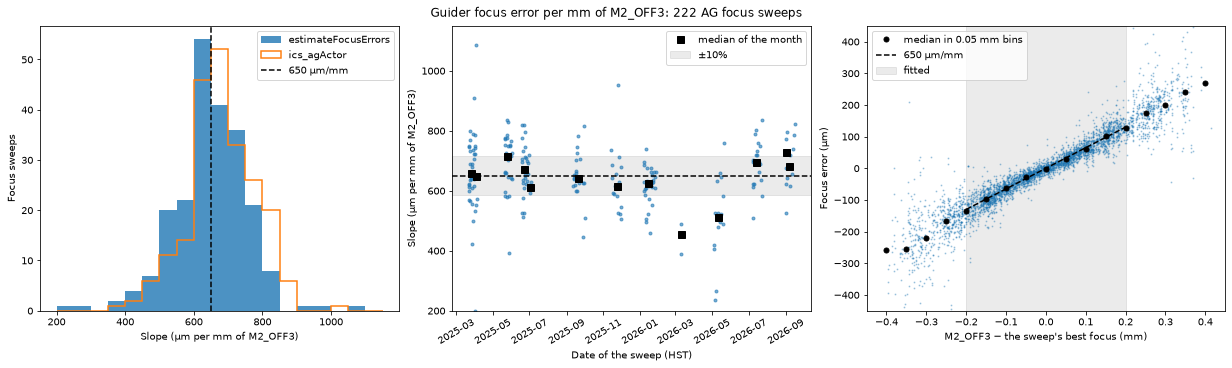

In [4]:
VALUE = coordinates.GUIDER_FOCUS_UM_PER_M2_OFF3_MM

fig, (axHist, axTime, axStack) = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)

bins = np.arange(200, 1151, 50)
axHist.hist(sweeps.slope.dropna(), bins=bins, color="C0", alpha=0.8, label="estimateFocusErrors")
axHist.hist(
    sweeps.ag_actor_slope.dropna(), bins=bins, histtype="step", color="C1", lw=1.5, label="ics_agActor"
)
axHist.axvline(VALUE, color="black", ls="--", label=f"{VALUE:.0f} µm/mm")
axHist.set_xlabel("Slope (µm per mm of M2_OFF3)")
axHist.set_ylabel("Focus sweeps")
axHist.legend()

axTime.plot(sweeps.taken_at, sweeps.slope, ".", color="C0", alpha=0.6)
periods = sweeps.groupby("period").agg(taken_at=("taken_at", "median"), slope=("slope", "median"))
axTime.plot(periods.taken_at, periods.slope, "s", color="black", ms=7, label="median of the month")
axTime.axhline(VALUE, color="black", ls="--")
axTime.axhspan(0.9 * VALUE, 1.1 * VALUE, color="black", alpha=0.08, label="±10%")
axTime.set_ylim(200, 1150)
axTime.set_xlabel("Date of the sweep (HST)")
axTime.set_ylabel("Slope (µm per mm of M2_OFF3)")
axTime.tick_params(axis="x", rotation=30)
axTime.legend()

offset = exposures.focus_position_mm - exposures.pfs_visit_id.map(sweeps.best_focus_mm)
axStack.plot(offset, exposures.focus_error_um, ".", color="C0", ms=2, alpha=0.3)
binned = exposures.focus_error_um.groupby((offset / 0.05).round() * 0.05).median()
binned = binned[np.abs(binned.index) <= 0.4]
axStack.plot(binned.index, binned, "o", color="black", ms=5, label="median in 0.05 mm bins")
x = np.array([-HALF_RANGE_MM, HALF_RANGE_MM])
axStack.plot(x, coordinates.m2Off3ToGuiderFocus(x), color="black", ls="--", label=f"{VALUE:.0f} µm/mm")
axStack.axvspan(-HALF_RANGE_MM, HALF_RANGE_MM, color="black", alpha=0.08, label="fitted")
axStack.set_xlim(-0.45, 0.45)
axStack.set_ylim(-450, 450)
axStack.set_xlabel("M2_OFF3 − the sweep's best focus (mm)")
axStack.set_ylabel("Focus error (µm)")
axStack.legend()

fig.suptitle(f"Guider focus error per mm of M2_OFF3: {sweeps.slope.notna().sum()} AG focus sweeps");

Left: the sweeps' slopes. Middle: each sweep's slope against its date, with the median of each month's sweeps (one
observing run or less). Right: every AG exposure of every sweep about its sweep's best focus; the focus error is
linear within the fitted range and flattens beyond it.

## By month and by camera

In [5]:
byPeriod = sweeps.groupby("period").agg(
    first_visit=("slope", lambda slopes: slopes.index.min()),
    last_visit=("slope", lambda slopes: slopes.index.max()),
    sweeps=("slope", "count"),
    median=("slope", "median"),
    scatter=("slope", robustScatter),
    ag_actor_median=("ag_actor_slope", "median"),
)
byPeriod.round(0).astype(int)

,first_visit,last_visit,sweeps,median,scatter,ag_actor_median
period,,,,,,
2025-03,121267,123258,35,659,73,753
2025-04,123283,123617,8,649,156,732
2025-05,125452,126808,25,716,86,705
2025-06,126900,128964,28,674,73,681
2025-07,129075,129215,2,611,29,624
2025-09,129685,132332,21,643,40,650
2025-11,133647,135699,17,617,90,640
2026-01,136362,139719,30,627,47,645
2026-03,140052,140362,3,454,54,483


In [6]:
cameraNames = [f"AG{i}" for i in range(1, 7)]
pd.DataFrame({name: summarize(sweeps[name]) for name in cameraNames}).T.round(0).astype(int)

,sweeps,median,scatter,error of median
AG1,168,606,110,11
AG2,170,737,111,11
AG3,177,667,86,8
AG4,187,661,85,8
AG5,189,660,87,8
AG6,194,765,97,9


- Months with at least eight sweeps have medians from 513 to 716 µm/mm; the lowest is May 2026.
- The cameras' medians run from 606 µm/mm (AG1) to 765 (AG6): AG2 and AG6 are steeper than the other four.

One constant for every camera and date is therefore good to about 10%, which is what the expected-focus line and the
M2_OFF3 axis of the focus plots need. A measurement that needs better should fit its own sweep with
`analysis.fitFocusSlope`.